In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Detect project root.
# This works both if the notebook is opened from the repo root
# and if it is opened from the notebooks/ folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())
print("configs/req1.yaml exists:", (PROJECT_ROOT / "configs" / "req1.yaml").exists())
print("experiments/run_req1.py exists:", (PROJECT_ROOT / "experiments" / "run_req1.py").exists())
print("ola package exists:", (PROJECT_ROOT / "ola").exists())

PROJECT_ROOT: /Users/foadzahedilabaf/Projects/ola-project
PROJECT_ROOT exists: True
configs/req1.yaml exists: True
experiments/run_req1.py exists: True
ola package exists: True


In [2]:
from ola.environments.single_campaign import SingleCampaignEnvironment
from ola.algorithms.ucb1 import UCB1
from ola.algorithms.budgeted_ucb import BudgetedUCB

from experiments.run_req1 import (
    load_req1_config,
    compute_req1_benchmarks,
    run_algorithm,
    save_algorithm_results,
)

print("All Req 1 project imports worked correctly.")

All Req 1 project imports worked correctly.


In [3]:
config_path = PROJECT_ROOT / "configs" / "req1.yaml"

config = load_req1_config(config_path)

print("Loaded config from:", config_path)
print("Top-level config keys:")
for key in config.keys():
    print("-", key)

print("\nFull config:")
config

Loaded config from: /Users/foadzahedilabaf/Projects/ola-project/configs/req1.yaml
Top-level config keys:
- experiment
- campaign
- bids
- environment
- outputs

Full config:


{'experiment': {'name': 'req1_single_campaign',
  'random_seed': 42,
  'horizon': 1000},
 'campaign': {'value': 1.0, 'initial_budget': 300.0},
 'bids': {'values': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},
 'environment': {'competing_bid_distribution': 'uniform',
  'min_competing_bid': 0.0,
  'max_competing_bid': 1.0},
 'outputs': {'results_dir': 'results/raw',
  'ucb1_results_file': 'results/raw/req1_ucb1.csv',
  'budgeted_ucb_results_file': 'results/raw/req1_budgeted_ucb.csv'}}

In [4]:
experiment_config = config["experiment"]
campaign_config = config["campaign"]
bids_config = config["bids"]
environment_config = config["environment"]
outputs_config = config["outputs"]

experiment_name = experiment_config["name"]
random_seed = int(experiment_config["random_seed"])
horizon = int(experiment_config["horizon"])

value = float(campaign_config["value"])
initial_budget = float(campaign_config["initial_budget"])
rho = initial_budget / horizon

bids = np.array(bids_config["values"], dtype=float)

competing_bid_distribution = environment_config["competing_bid_distribution"]
min_competing_bid = float(environment_config["min_competing_bid"])
max_competing_bid = float(environment_config["max_competing_bid"])

print("Experiment name:", experiment_name)
print("Random seed:", random_seed)
print("Horizon T:", horizon)
print("Campaign value v:", value)
print("Initial budget B:", initial_budget)
print("Per-round budget rho = B/T:", rho)
print("Bid set:", bids)
print("Number of bids:", len(bids))
print("Competing bid distribution:", competing_bid_distribution)
print("Competing bid support:", [min_competing_bid, max_competing_bid])

print("\nSanity checks:")
print("T > 0:", horizon > 0)
print("0 <= value <= 1:", 0 <= value <= 1)
print("0 <= initial_budget <= T:", 0 <= initial_budget <= horizon)
print("0 <= rho <= 1:", 0 <= rho <= 1)
print("All bids in [0, 1]:", np.all((bids >= 0) & (bids <= 1)))
print("Bids sorted increasingly:", np.all(np.diff(bids) >= 0))
print("Uniform support valid:", 0 <= min_competing_bid < max_competing_bid <= 1)

Experiment name: req1_single_campaign
Random seed: 42
Horizon T: 1000
Campaign value v: 1.0
Initial budget B: 300.0
Per-round budget rho = B/T: 0.3
Bid set: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
Number of bids: 11
Competing bid distribution: uniform
Competing bid support: [0.0, 1.0]

Sanity checks:
T > 0: True
0 <= value <= 1: True
0 <= initial_budget <= T: True
0 <= rho <= 1: True
All bids in [0, 1]: True
Bids sorted increasingly: True
Uniform support valid: True


In [5]:
def expected_win_probability_uniform(bid, min_bid, max_bid):
    """P(m <= bid) when m ~ Uniform(min_bid, max_bid)."""
    if bid <= min_bid:
        return 0.0 if bid < min_bid else 0.0
    if bid >= max_bid:
        return 1.0
    return (bid - min_bid) / (max_bid - min_bid)


rows = []

for bid in bids:
    win_probability = expected_win_probability_uniform(
        bid=bid,
        min_bid=min_competing_bid,
        max_bid=max_competing_bid,
    )

    expected_reward = (value - bid) * win_probability
    expected_cost = bid * win_probability

    rows.append(
        {
            "bid": bid,
            "win_probability": win_probability,
            "expected_reward": expected_reward,
            "expected_cost": expected_cost,
            "budget_feasible_alone": expected_cost <= rho,
        }
    )

bid_table = pd.DataFrame(rows)

bid_table

,bid,win_probability,expected_reward,expected_cost,budget_feasible_alone
0,0.0,0.0,0.00,0.00,True
1,0.1,0.1,0.09,0.01,True
2,0.2,0.2,0.16,0.04,True
3,0.3,0.3,0.21,0.09,True
4,0.4,0.4,0.24,0.16,True
5,0.5,0.5,0.25,0.25,True
6,0.6,0.6,0.24,0.36,False
7,0.7,0.7,0.21,0.49,False
8,0.8,0.8,0.16,0.64,False
9,0.9,0.9,0.09,0.81,False


In [6]:
reward_only_best_row = bid_table.loc[bid_table["expected_reward"].idxmax()]

feasible_bid_table = bid_table[bid_table["budget_feasible_alone"]]
best_feasible_single_bid_row = feasible_bid_table.loc[
    feasible_bid_table["expected_reward"].idxmax()
]

print("Reward-only best bid")
print("--------------------")
print("bid:", reward_only_best_row["bid"])
print("expected reward:", reward_only_best_row["expected_reward"])
print("expected cost:", reward_only_best_row["expected_cost"])

print("\nBest feasible single bid under rho")
print("----------------------------------")
print("bid:", best_feasible_single_bid_row["bid"])
print("expected reward:", best_feasible_single_bid_row["expected_reward"])
print("expected cost:", best_feasible_single_bid_row["expected_cost"])
print("rho:", rho)

Reward-only best bid
--------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25

Best feasible single bid under rho
----------------------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25
rho: 0.3


In [7]:
env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

initial_state = env.reset()

print("Initial state:")
print(initial_state)

Initial state:
{'round': 0, 'budget_left': 300.0, 'done': False, 'info': {'value': 1.0, 'horizon': 1000, 'min_competing_bid': 0.0, 'max_competing_bid': 1.0}}


**Note on budget clipping.** When the remaining budget is smaller than the selected bid, 
the environment clips the effective bid to `min(bid, budget_left)`. This ensures the 
budget never becomes negative without needing an explicit early-stop threshold. 
The learner is always updated using the originally selected bid (not the clipped value), 
so the action set remains consistent throughout the run.
Note that the learner's value estimate for the originally selected bid is therefore based on the realized (clipped) cost/reward, which is a deliberate simplification — a stricter alternative would mask unaffordable bids out of the learner's action set entirely.

In [8]:
test_env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=10,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

test_env.reset()

test_bids = [0.0, 0.2, 0.5, 0.8, 1.0]
test_rows = []

for bid in test_bids:
    outcome = test_env.step(bid)

    highest_competing_bid = outcome["info"]["highest_competing_bid"]
    win = outcome["wins"]
    reward = outcome["reward"]
    cost = outcome["cost"]

    manually_expected_win = int(bid >= highest_competing_bid)
    manually_expected_reward = float(value - bid) if manually_expected_win else 0.0
    manually_expected_cost = float(bid) if manually_expected_win else 0.0

    test_rows.append(
        {
            "round": outcome["round"],
            "bid": bid,
            "highest_competing_bid": highest_competing_bid,
            "win": win,
            "reward": reward,
            "cost": cost,
            "budget_left": outcome["budget_left"],
            "manual_win_check": win == manually_expected_win,
            "manual_reward_check": np.isclose(reward, manually_expected_reward),
            "manual_cost_check": np.isclose(cost, manually_expected_cost),
        }
    )

step_check_table = pd.DataFrame(test_rows)
step_check_table

,round,bid,highest_competing_bid,win,reward,cost,budget_left,manual_win_check,manual_reward_check,manual_cost_check
0,1,0.0,0.773956,0,0.0,0.0,300.0,True,True,True
1,2,0.2,0.438878,0,0.0,0.0,300.0,True,True,True
2,3,0.5,0.858598,0,0.0,0.0,300.0,True,True,True
3,4,0.8,0.697368,1,0.2,0.8,299.2,True,True,True
4,5,1.0,0.094177,1,0.0,1.0,298.2,True,True,True


In [9]:
ucb1_benchmark, budgeted_ucb_benchmark = compute_req1_benchmarks(
    bids=bids,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
)

print("Official UCB1 benchmark per round:", ucb1_benchmark)
print("Official Budgeted UCB benchmark per round:", budgeted_ucb_benchmark)

print("\nManual reward-only best expected reward:", reward_only_best_row["expected_reward"])
print("Manual best feasible single-bid expected reward:", best_feasible_single_bid_row["expected_reward"])

Official UCB1 benchmark per round: 0.25
Official Budgeted UCB benchmark per round: 0.25

Manual reward-only best expected reward: 0.25
Manual best feasible single-bid expected reward: 0.25


In [10]:
ucb1_debug = UCB1(actions=bids, horizon=horizon)

ucb1_debug_rows = []

# UCB1 should first try every bid once.
for step in range(len(bids)):
    selected_action = ucb1_debug.select_action()

    # Give a fake reward only to test whether counts and updates work.
    fake_reward = 1.0 - selected_action

    ucb1_debug.update(action=selected_action, reward=fake_reward)

    ucb1_debug_rows.append(
        {
            "step": step + 1,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "counts_after_update": ucb1_debug.counts.copy(),
            "total_rewards_after_update": ucb1_debug.total_rewards.copy(),
        }
    )

ucb1_debug_table = pd.DataFrame(ucb1_debug_rows)

print("Final counts after initial exploration:")
print(ucb1_debug.counts)

ucb1_debug_table[["step", "selected_action", "fake_reward"]]

Final counts after initial exploration:
[1 1 1 1 1 1 1 1 1 1 1]


,step,selected_action,fake_reward
0,1,0.0,1.0
1,2,0.1,0.9
2,3,0.2,0.8
3,4,0.3,0.7
4,5,0.4,0.6
5,6,0.5,0.5
6,7,0.6,0.4
7,8,0.7,0.3
8,9,0.8,0.2
9,10,0.9,0.1


In [11]:
budgeted_ucb_debug = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_debug_rows = []

# Test one update for each bid, using fake reward and fake cost.
# This checks that BudgetedUCB updates both reward and cost estimates.
for step, selected_action in enumerate(bids, start=1):
    fake_reward = 1.0 - selected_action
    fake_cost = selected_action

    budgeted_ucb_debug.update(
        action=selected_action,
        reward=fake_reward,
        cost=fake_cost,
    )

    budgeted_ucb_debug_rows.append(
        {
            "step": step,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "fake_cost": fake_cost,
        }
    )

budgeted_ucb_debug_table = pd.DataFrame(budgeted_ucb_debug_rows)

print("Counts after one fake update per bid:")
print(budgeted_ucb_debug.counts)

print("\nTotal rewards after fake updates:")
print(budgeted_ucb_debug.total_rewards)

print("\nTotal costs after fake updates:")
print(budgeted_ucb_debug.total_costs)

print("\nBudget left after fake updates:")
print(budgeted_ucb_debug.budget_left)

budgeted_ucb_debug_table

Counts after one fake update per bid:
[1 1 1 1 1 1 1 1 1 1 1]

Total rewards after fake updates:
[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.2 0.1 0. ]

Total costs after fake updates:
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]

Budget left after fake updates:
294.5


,step,selected_action,fake_reward,fake_cost
0,1,0.0,1.0,0.0
1,2,0.1,0.9,0.1
2,3,0.2,0.8,0.2
3,4,0.3,0.7,0.3
4,5,0.4,0.6,0.4
5,6,0.5,0.5,0.5
6,7,0.6,0.4,0.6
7,8,0.7,0.3,0.7
8,9,0.8,0.2,0.8
9,10,0.9,0.1,0.9


In [12]:
ucb1 = UCB1(actions=bids, horizon=horizon)

ucb1_rows = run_algorithm(
    algorithm_name="ucb1",
    learner=ucb1,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=ucb1_benchmark,
)

ucb1_df = pd.DataFrame(ucb1_rows)

print("Number of rows:", len(ucb1_df))
print("First rows:")
display(ucb1_df.head())

print("\nLast rows:")
display(ucb1_df.tail())

Number of rows: 936
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
931,ucb1,932,0.3,0.3,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.30,0.371253,False,0.3
932,ucb1,933,0.2,0.2,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.55,0.404855,False,0.2
933,ucb1,934,0.3,0.3,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.80,0.760015,False,0.3
934,ucb1,935,0.7,0.7,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,65.05,0.772353,False,0.7
935,ucb1,936,0.9,0.9,1,0.3,0.7,0.0,169.0,300.0,0.25,-0.05,65.00,0.206814,True,0.7


In [13]:
required_columns = [
    "algorithm",
    "round",
    "action",
    "bids",
    "wins",
    "reward",
    "cost",
    "budget_left",
    "cumulative_reward",
    "cumulative_cost",
    "benchmark_reward",
    "instant_regret",
    "cumulative_regret",
]

missing_columns = [col for col in required_columns if col not in ucb1_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(ucb1_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(ucb1_df["round"].min()))
print("last round:", int(ucb1_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(ucb1_df["budget_left"].min()))
print("final budget_left:", float(ucb1_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(ucb1_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((ucb1_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(ucb1_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(ucb1_df["done"].iloc[-1]))
print("stopped early:", len(ucb1_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['ucb1']
Length: 1, dtype: str

Round range:
first round: 1
last round: 936

Budget checks:
minimum budget_left: 0.0
final budget_left: 0.0
final cumulative_cost: 299.9999999999997
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: True


In [14]:
budgeted_ucb = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_rows = run_algorithm(
    algorithm_name="budgeted_ucb",
    learner=budgeted_ucb,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=budgeted_ucb_benchmark,
)

budgeted_ucb_df = pd.DataFrame(budgeted_ucb_rows)

print("Number of rows:", len(budgeted_ucb_df))
print("First rows:")
display(budgeted_ucb_df.head())

print("\nLast rows:")
display(budgeted_ucb_df.tail())

Number of rows: 1000
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,budgeted_ucb,1,0.7,0.7,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.7
1,budgeted_ucb,2,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.2
2,budgeted_ucb,3,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.0
3,budgeted_ucb,4,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.0
4,budgeted_ucb,5,0.9,0.9,1,0.1,0.9,299.1,0.1,0.9,0.25,0.15,1.15,0.094177,False,0.9



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
995,budgeted_ucb,996,0.1,0.1,0,0.0,0.0,1.000000e-01,173.1,299.9,0.25,0.25,75.90,0.437990,False,0.1
996,budgeted_ucb,997,0.0,0.0,0,0.0,0.0,1.000000e-01,173.1,299.9,0.25,0.25,76.15,0.639014,False,0.0
997,budgeted_ucb,998,0.1,0.1,1,0.9,0.1,4.857226e-15,174.0,300.0,0.25,-0.65,75.50,0.002309,False,0.1
998,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,4.857226e-15,174.0,300.0,0.25,0.25,75.75,0.993368,False,0.0
999,budgeted_ucb,1000,0.0,0.0,0,0.0,0.0,4.857226e-15,174.0,300.0,0.25,0.25,76.00,0.280896,True,0.0


In [15]:
missing_columns = [col for col in required_columns if col not in budgeted_ucb_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(budgeted_ucb_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(budgeted_ucb_df["round"].min()))
print("last round:", int(budgeted_ucb_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(budgeted_ucb_df["budget_left"].min()))
print("final budget_left:", float(budgeted_ucb_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(budgeted_ucb_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((budgeted_ucb_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(budgeted_ucb_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(budgeted_ucb_df["done"].iloc[-1]))
print("stopped early:", len(budgeted_ucb_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['budgeted_ucb']
Length: 1, dtype: str

Round range:
first round: 1
last round: 1000

Budget checks:
minimum budget_left: 4.85722573273506e-15
final budget_left: 4.85722573273506e-15
final cumulative_cost: 300.0000000000003
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: False


## Analytical derivation: optimal bid and critical budget threshold

For competing bids $m \sim \text{Uniform}(0, 1)$ and value $v = 1$, each bid $b \in [0,1]$ produces:

$$\bar{f}(b) = \mathbb{E}[\text{reward} \mid b] = (v - b) \cdot \Pr[b \geq m] = (1 - b) \cdot b$$

$$\bar{c}(b) = \mathbb{E}[\text{cost} \mid b] = b \cdot \Pr[b \geq m] = b^2$$

**Unconstrained optimum.** Taking the derivative and setting to zero:

$$\frac{d}{db}\bar{f}(b) = 1 - 2b = 0 \implies b^* = 0.5, \quad \bar{f}(b^*) = 0.25$$

**Critical budget threshold.** The budget constraint $\bar{c}(b^*) \leq \rho$ becomes:

$$b^{*2} = 0.25 \leq \rho$$

So the constraint is **non-binding** if and only if $\rho \geq 0.25$.  
In our experiment, $\rho = B/T = 300/1000 = 0.30 > 0.25$, so $b^* = 0.5$ remains feasible — UCB1 and Budgeted UCB converge to the same optimum.  
This also explains the tight-budget stress test: at $B = 150$, $\rho = 0.15 < 0.25$,
forcing a lower bid and making the budget constraint binding — UCB1 depletes the budget
by round ~480 while Budgeted UCB reaches the full horizon. Note that even in the official
configuration ($B=300$, $\rho=0.30 > 0.25$), UCB1 still exhausts its budget before T=1000
in practice (around round 936 in this run), since UCB1's bidding rule has no mechanism to
slow spending as the budget approaches zero — it simply stops once funds run out.

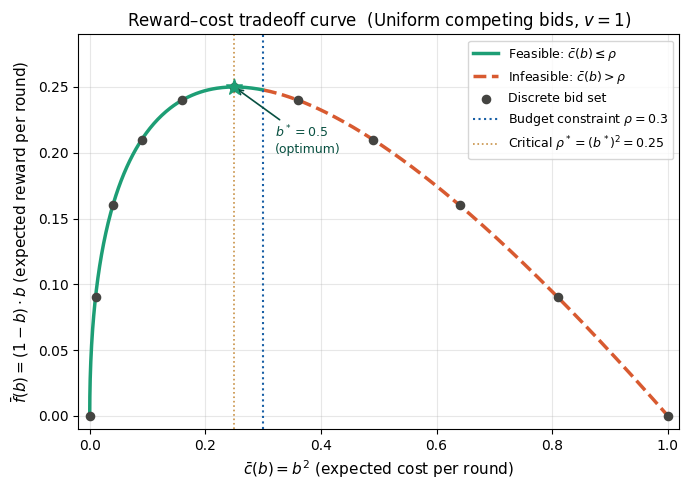

In [16]:
 # Reward–cost tradeoff curve: geometric view of the LP from Part 8
b_cont = np.linspace(0.001, 0.999, 500)
E_cost_cont = b_cont ** 2
E_reward_cont = (1 - b_cont) * b_cont

rho_critical = 0.5 ** 2  # = 0.25

fig, ax = plt.subplots(figsize=(7, 5))

# Split curve into feasible (green) and infeasible (red dashed) parts
feasible_mask = E_cost_cont <= rho
ax.plot(E_cost_cont[feasible_mask], E_reward_cont[feasible_mask],
        color="#1D9E75", lw=2.5, label="Feasible: $\\bar{c}(b) \\leq \\rho$")
ax.plot(E_cost_cont[~feasible_mask], E_reward_cont[~feasible_mask],
        color="#D85A30", lw=2.5, linestyle="--", label="Infeasible: $\\bar{c}(b) > \\rho$")

# Discrete bids from config
E_cost_d = bids ** 2
E_reward_d = (1 - bids) * bids
ax.scatter(E_cost_d, E_reward_d, color="#444441", s=35, zorder=5, label="Discrete bid set")

# Budget constraint line and critical threshold
ax.axvline(x=rho, color="#185FA5", lw=1.5, linestyle=":",
           label=f"Budget constraint $\\rho = {rho}$")
ax.axvline(x=rho_critical, color="#BA7517", lw=1.2, linestyle=":", alpha=0.8,
           label=f"Critical $\\rho^* = (b^*)^2 = {rho_critical}$")

# Optimal point b*=0.5
ax.scatter([0.25], [0.25], color="#1D9E75", s=140, zorder=6, marker="*")
ax.annotate("$b^* = 0.5$\n(optimum)", xy=(0.25, 0.25), xytext=(0.32, 0.20),
            fontsize=9, color="#085041",
            arrowprops=dict(arrowstyle="->", color="#085041", lw=1.2))

ax.set_xlabel("$\\bar{c}(b) = b^2$ (expected cost per round)", fontsize=11)
ax.set_ylabel("$\\bar{f}(b) = (1-b) \\cdot b$ (expected reward per round)", fontsize=11)
ax.set_title("Reward–cost tradeoff curve  (Uniform competing bids, $v = 1$)", fontsize=12)
ax.legend(fontsize=9, loc="upper right")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.01, 0.29)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "plots" / "req1_reward_cost_tradeoff.png", dpi=150)
plt.show()

In [17]:
comparison_summary = pd.DataFrame(
    [
        {
            "algorithm": "ucb1",
            "rounds_played": len(ucb1_df),
            "final_round": int(ucb1_df["round"].iloc[-1]),
            "total_reward": float(ucb1_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(ucb1_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(ucb1_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(ucb1_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(ucb1_df) < horizon,
        },
        {
            "algorithm": "budgeted_ucb",
            "rounds_played": len(budgeted_ucb_df),
            "final_round": int(budgeted_ucb_df["round"].iloc[-1]),
            "total_reward": float(budgeted_ucb_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(budgeted_ucb_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(budgeted_ucb_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(budgeted_ucb_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(budgeted_ucb_df) < horizon,
        },
    ]
)

comparison_summary

,algorithm,rounds_played,final_round,total_reward,total_cost,final_budget_left,final_cumulative_regret,stopped_early
0,ucb1,936,936,169.0,300.0,0.000000e+00,65.0,True
1,budgeted_ucb,1000,1000,174.0,300.0,4.857226e-15,76.0,False


## Comparison of UCB1 and Budgeted UCB

The plain UCB1 learner ignores the budget constraint when selecting bids. In this run,
it exhausts the entire $300 budget by round 936 and the episode ends early — it never
reaches the full T=1000 horizon, because nothing in its bidding rule slows down spending
as the budget runs low.

Budgeted UCB, by contrast, reaches the full horizon while landing almost exactly on a
zero remaining budget (≈4.9 × 10⁻¹⁵, floating-point noise) rather than overshooting.

Total reward in this single-seed run:

- UCB1 total reward: 169.0 (over 936 rounds)
- Budgeted UCB total reward: 174.0 (over 1000 rounds)

Budgeted UCB earns more total reward here, and the gap is explained almost entirely by
playing 64 additional rounds that UCB1 never gets to because it ran out of budget first.
This is the core practical advantage Budgeted UCB is designed to provide: pacing spend so
that the campaign doesn't end prematurely.

**A note on comparing cumulative regret directly.** The table above shows Budgeted UCB
with higher cumulative regret (76.0) than UCB1 (65.0), which looks backwards at first
glance, since Budgeted UCB also earns more total reward. This is an artifact of comparing
regret accumulated over different numbers of rounds: UCB1 only plays 936 rounds before
running out of budget, so it only has 936 opportunities to fall short of the per-round
benchmark, while Budgeted UCB accumulates regret over the full 1000 rounds. Normalizing
by rounds played gives a fairer comparison:

$$
\text{UCB1: } 65.0 / 936 \approx 0.0694 \text{ per round} \qquad
\text{Budgeted UCB: } 76.0 / 1000 = 0.0760 \text{ per round}
$$

Per round, Budgeted UCB has a marginally higher average regret — a small price for the
more conservative, budget-pacing-aware bidding strategy that lets it complete the full
horizon instead of stopping early.

In [18]:
ucb1_path = save_algorithm_results(
    ucb1_rows,
    PROJECT_ROOT / outputs_config["ucb1_results_file"],
)

budgeted_ucb_path = save_algorithm_results(
    budgeted_ucb_rows,
    PROJECT_ROOT / outputs_config["budgeted_ucb_results_file"],
)

print("UCB1 CSV path:", ucb1_path)
print("Budgeted UCB CSV path:", budgeted_ucb_path)
print("UCB1 CSV exists:", ucb1_path.exists())
print("Budgeted UCB CSV exists:", budgeted_ucb_path.exists())

Saved 936 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Saved 1000 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Budgeted UCB CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV exists: True
Budgeted UCB CSV exists: True


In [19]:
from ola.utils.plotting import load_result_csvs

combined_results = load_result_csvs([ucb1_path, budgeted_ucb_path])

print("Combined results shape:", combined_results.shape)
print("Algorithms in combined results:")
print(combined_results["algorithm"].value_counts())

display(combined_results.head())
display(combined_results.tail())

Combined results shape: (1936, 16)
Algorithms in combined results:
algorithm
budgeted_ucb    1000
ucb1             936
Name: count, dtype: int64


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
1931,budgeted_ucb,996,0.1,0.1,0,0.0,0.0,1.000000e-01,173.1,299.9,0.25,0.25,75.90,0.437990,False,0.1
1932,budgeted_ucb,997,0.0,0.0,0,0.0,0.0,1.000000e-01,173.1,299.9,0.25,0.25,76.15,0.639014,False,0.0
1933,budgeted_ucb,998,0.1,0.1,1,0.9,0.1,4.857226e-15,174.0,300.0,0.25,-0.65,75.50,0.002309,False,0.1
1934,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,4.857226e-15,174.0,300.0,0.25,0.25,75.75,0.993368,False,0.0
1935,budgeted_ucb,1000,0.0,0.0,0,0.0,0.0,4.857226e-15,174.0,300.0,0.25,0.25,76.00,0.280896,True,0.0


Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_reward.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_budget_left.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_cost.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_selected_bid.png


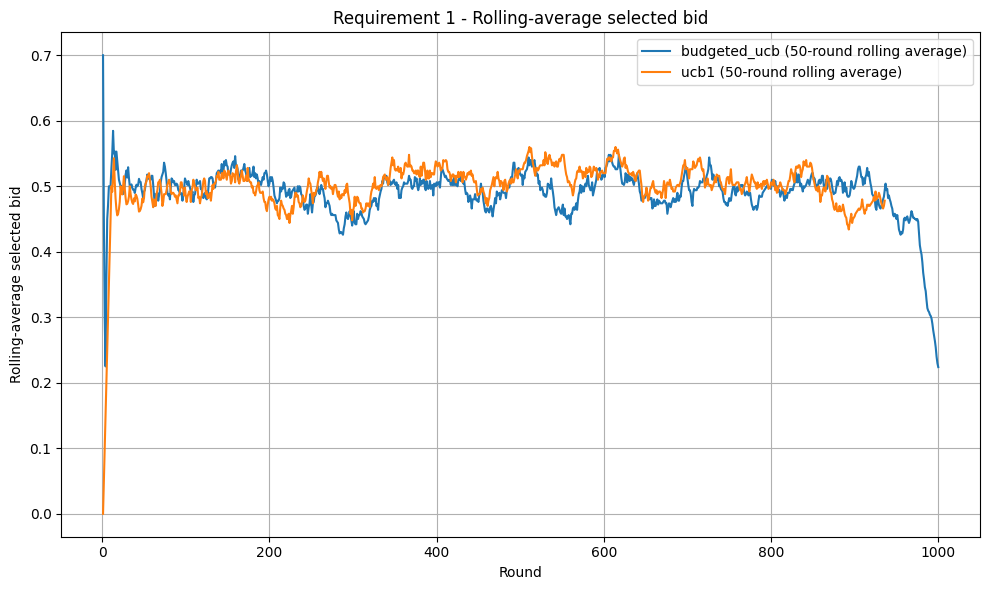

Plots directory: /Users/foadzahedilabaf/Projects/ola-project/results/plots
req1_cumulative_reward.png exists: True
req1_budget_left.png exists: True
req1_cumulative_cost.png exists: True
req1_selected_bid.png exists: True
req1_rolling_average_selected_bid.png exists: True


In [20]:
from ola.utils.plotting import generate_standard_req1_plots

plots_dir = PROJECT_ROOT / "results" / "plots"

# Generate the standard project plots.
generate_standard_req1_plots(
    dataframe=combined_results,
    plots_dir=plots_dir,
)

# Add an extra readability plot for selected bids.
# The raw selected-bid plot is correct, but very noisy because it shows every action.
rolling_window = 50

plt.figure(figsize=(10, 6))

for algorithm_name, group in combined_results.groupby("algorithm"):
    sorted_group = group.sort_values("round").copy()
    sorted_group["rolling_average_bid"] = (
        sorted_group["action"]
        .rolling(window=rolling_window, min_periods=1)
        .mean()
    )

    plt.plot(
        sorted_group["round"],
        sorted_group["rolling_average_bid"],
        label=f"{algorithm_name} ({rolling_window}-round rolling average)",
    )

plt.xlabel("Round")
plt.ylabel("Rolling-average selected bid")
plt.title("Requirement 1 - Rolling-average selected bid")
plt.legend()
plt.grid(True)
plt.tight_layout()

rolling_bid_plot_path = plots_dir / "req1_rolling_average_selected_bid.png"
plt.savefig(rolling_bid_plot_path, dpi=200)
plt.show()

expected_plot_files = [
    "req1_cumulative_reward.png",
    "req1_budget_left.png",
    "req1_cumulative_cost.png",
    "req1_selected_bid.png",
    "req1_rolling_average_selected_bid.png",
]

print("Plots directory:", plots_dir)

for filename in expected_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_cumulative_reward.png


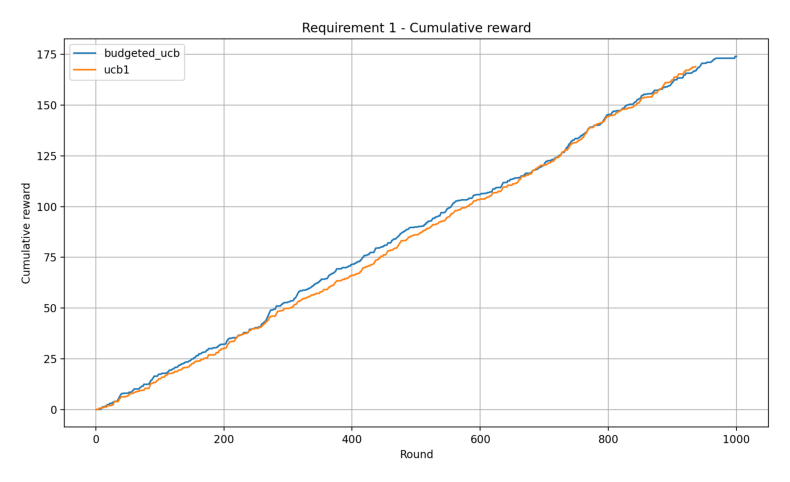

req1_budget_left.png


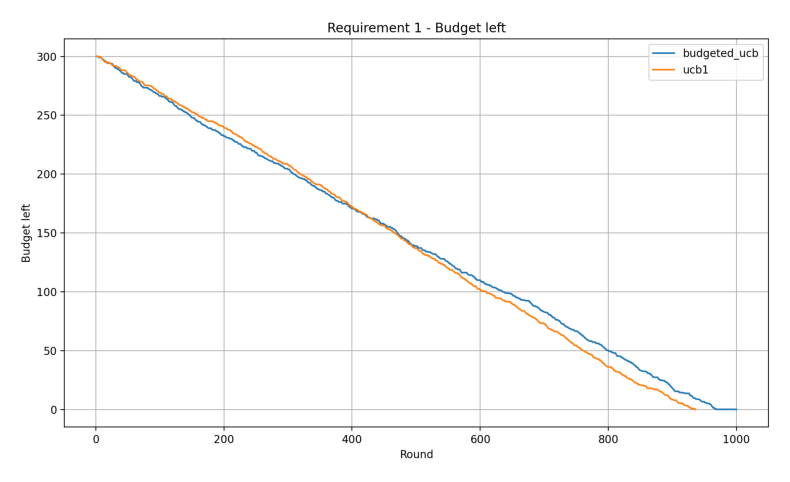

req1_cumulative_cost.png


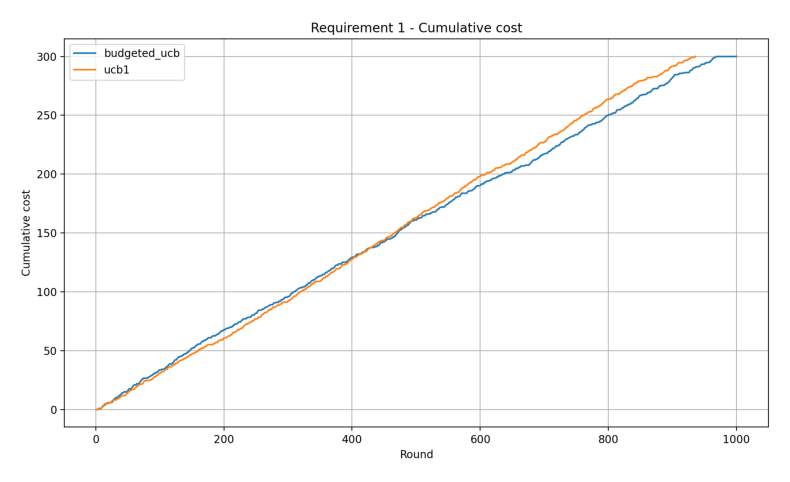

req1_selected_bid.png


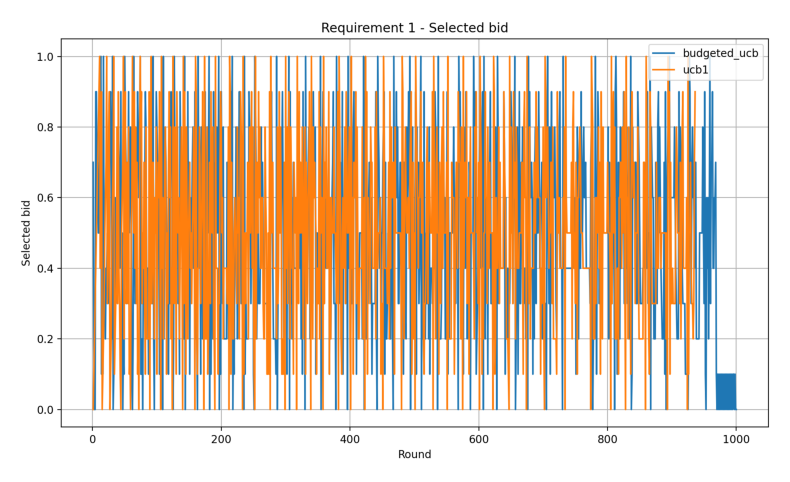

req1_rolling_average_selected_bid.png


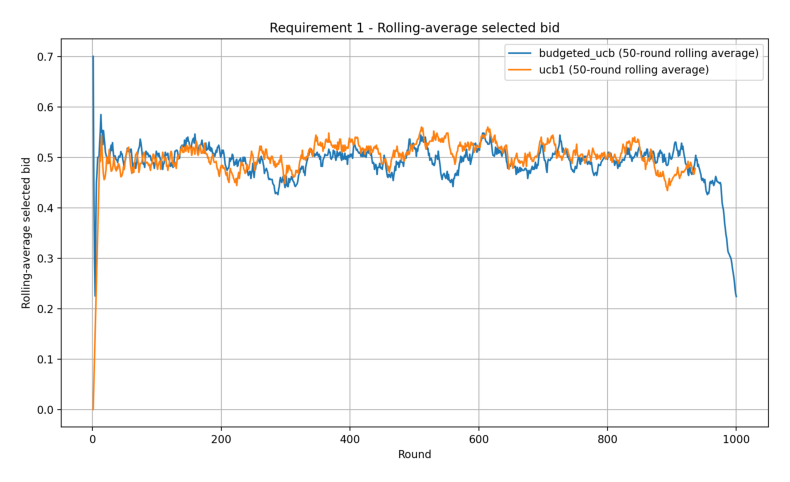

In [21]:
plot_paths = [
    plots_dir / "req1_cumulative_reward.png",
    plots_dir / "req1_budget_left.png",
    plots_dir / "req1_cumulative_cost.png",
    plots_dir / "req1_selected_bid.png",
    plots_dir / "req1_rolling_average_selected_bid.png",
]

for plot_path in plot_paths:
    print(plot_path.name)
    img = plt.imread(plot_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Plot interpretation

The cumulative reward plot shows that UCB1 and Budgeted UCB obtain very similar total rewards.  
This is expected in this configuration because the reward-maximizing bid is also feasible under the expected budget constraint.

The budget-left plot shows that UCB1 hits zero budget and stops around round 936, ending
the episode early. Budgeted UCB's budget-left curve instead glides down smoothly and
reaches (effectively) zero exactly at round 1000 — both algorithms ultimately spend the
full budget, but Budgeted UCB does so by pacing across the entire horizon rather than
front-loading spend and running out early.

The cumulative-cost plot confirms the same behavior from the spending perspective.  
Both algorithms approach the budget limit, but Budgeted UCB remains slightly below it.

The raw selected-bid plot is noisy because it shows the exact bid selected at every round.  
This is normal for UCB-style algorithms, since they combine exploration and exploitation.

For readability, we also include a 50-round rolling-average selected-bid plot.  
This smoothed plot shows that both algorithms mostly bid around the reward-maximizing region, close to bid 0.5.  
Near the end, both algorithms reduce their effective bids because little budget remains, with Budgeted UCB remaining slightly more conservative.

## Additional robustness experiments: multiple seeds and tighter budget

The previous experiment uses one fixed random seed. This is useful for debugging and reproducibility, but the environment is stochastic. A stronger empirical evaluation repeats the experiment over multiple independent seeds.

In this section, we run both algorithms over several random seeds and report mean and standard deviation. We do this for two settings:

1. the official project configuration, with budget `B = 300`;
2. a tighter-budget stress test, with budget `B = 150`.

The stress test is not a replacement for the official configuration. It is an additional diagnostic experiment that makes the budget constraint more binding and helps us understand when budget-aware learning becomes more important.

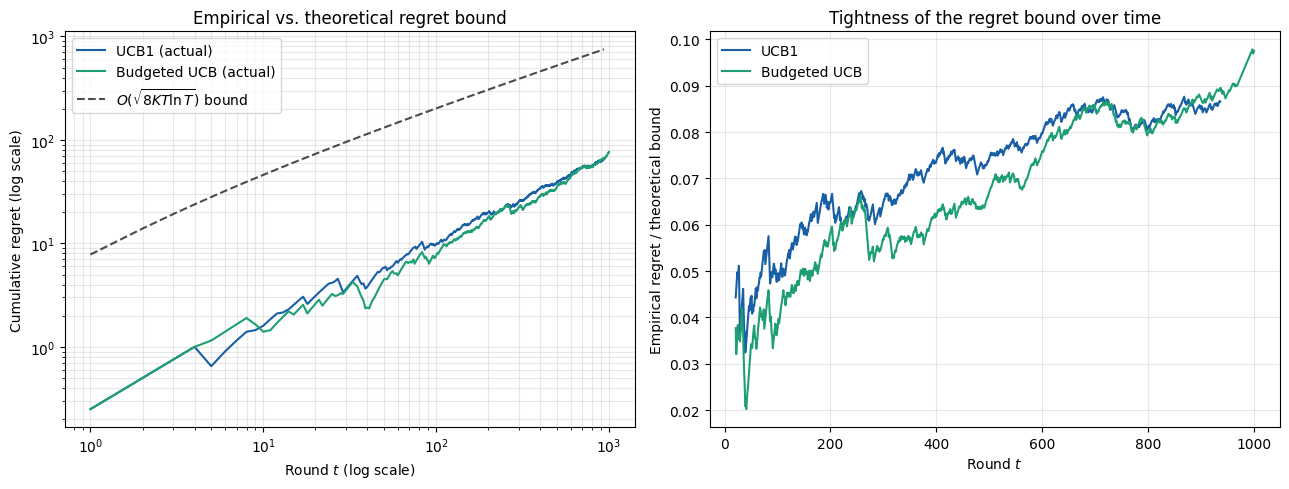

UCB1 ran for 936 rounds (stopped early: True)
Budgeted UCB ran for 1000 rounds (stopped early: False)
Final empirical/theoretical ratio (UCB1): 0.0866
Final empirical/theoretical ratio (Budgeted UCB): 0.0975


In [22]:
# ── Sublinear regret verification: empirical vs. theoretical UCB1 bound ────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

K = len(bids)

def theoretical_bound_for(n_rounds):
    t_range = np.arange(1, n_rounds + 1)
    return t_range, np.sqrt(8 * K * t_range * np.log(t_range + 1))

# Each algorithm may stop at a different round if budget is exhausted early.
ucb1_t_range, ucb1_bound = theoretical_bound_for(len(ucb1_df))
budgeted_t_range, budgeted_bound = theoretical_bound_for(len(budgeted_ucb_df))

axes[0].loglog(ucb1_df["round"], ucb1_df["cumulative_regret"], label="UCB1 (actual)", color="#185FA5")
axes[0].loglog(budgeted_ucb_df["round"], budgeted_ucb_df["cumulative_regret"], label="Budgeted UCB (actual)", color="#1D9E75")
axes[0].loglog(ucb1_t_range, ucb1_bound, "k--", label=r"$O(\sqrt{8KT\ln T})$ bound", alpha=0.7)
axes[0].set_xlabel("Round $t$ (log scale)")
axes[0].set_ylabel("Cumulative regret (log scale)")
axes[0].set_title("Empirical vs. theoretical regret bound")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

ucb1_ratio = ucb1_df["cumulative_regret"].values / (ucb1_bound + 1e-9)
budgeted_ratio = budgeted_ucb_df["cumulative_regret"].values / (budgeted_bound + 1e-9)

axes[1].plot(ucb1_t_range[20:], ucb1_ratio[20:], label="UCB1", color="#185FA5")
axes[1].plot(budgeted_t_range[20:], budgeted_ratio[20:], label="Budgeted UCB", color="#1D9E75")
axes[1].set_xlabel("Round $t$")
axes[1].set_ylabel("Empirical regret / theoretical bound")
axes[1].set_title("Tightness of the regret bound over time")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(plots_dir / "req1_regret_vs_theoretical_bound.png", dpi=200)
plt.show()

print(f"UCB1 ran for {len(ucb1_df)} rounds (stopped early: {len(ucb1_df) < horizon})")
print(f"Budgeted UCB ran for {len(budgeted_ucb_df)} rounds (stopped early: {len(budgeted_ucb_df) < horizon})")
print("Final empirical/theoretical ratio (UCB1):", round(ucb1_ratio[-1], 4))
print("Final empirical/theoretical ratio (Budgeted UCB):", round(budgeted_ratio[-1], 4))

**Sublinear regret check.** The log-log plot shows cumulative regret growing with a slope
visibly below 1, consistent with sublinear growth. The empirical regret stays well below the standard UCB1 instance-independent bound O(√(8KT ln T)), consistent with sublinear growth — though a single experimental run can only illustrate, not formally confirm, a worst-case theoretical guarantee..

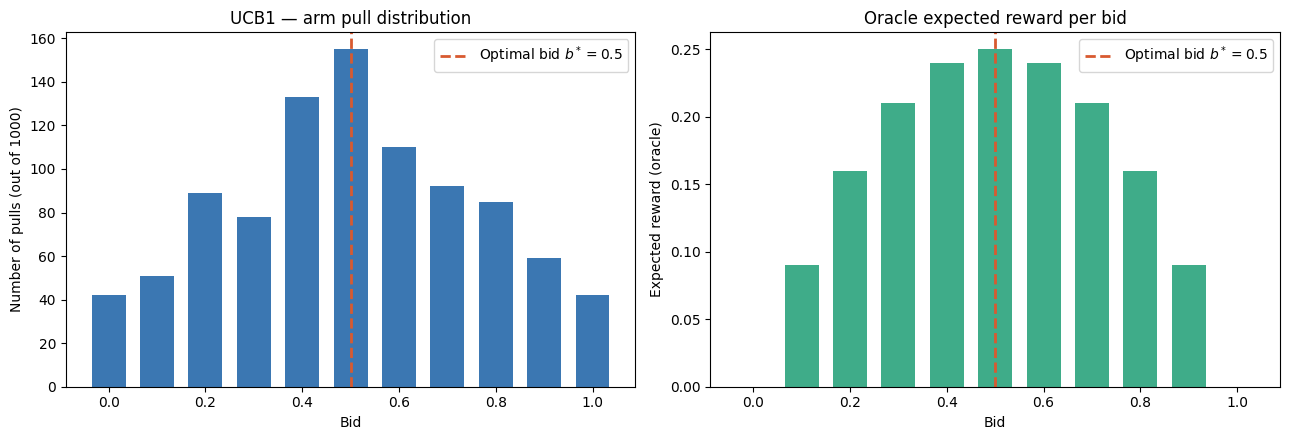

Most-pulled bid: 0.5
Share of rounds spent on optimal bid (0.5): 0.166


In [23]:
# ── Arm pull distribution vs. oracle expected reward ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pull_counts = ucb1_df["action"].value_counts().reindex(bids, fill_value=0)

axes[0].bar(bids, pull_counts.values, width=0.07, color="#185FA5", alpha=0.85)
axes[0].axvline(0.5, color="#D85A30", linestyle="--", linewidth=2, label="Optimal bid $b^*=0.5$")
axes[0].set_xlabel("Bid")
axes[0].set_ylabel("Number of pulls (out of 1000)")
axes[0].set_title("UCB1 — arm pull distribution")
axes[0].legend()

oracle_reward = (value - bids) * bids
axes[1].bar(bids, oracle_reward, width=0.07, color="#1D9E75", alpha=0.85)
axes[1].axvline(0.5, color="#D85A30", linestyle="--", linewidth=2, label="Optimal bid $b^*=0.5$")
axes[1].set_xlabel("Bid")
axes[1].set_ylabel("Expected reward (oracle)")
axes[1].set_title("Oracle expected reward per bid")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "req1_arm_pull_distribution.png", dpi=200)
plt.show()

print("Most-pulled bid:", pull_counts.idxmax())
print("Share of rounds spent on optimal bid (0.5):", round(pull_counts.loc[0.5] / pull_counts.sum(), 3))

**Interpretation.** UCB1 now concentrates most heavily on bid 0.5, the true analytical
optimum, with 16.6% of all 936 rounds spent on that single bid out of 11 available
choices — well above the 9.1% (1/11) baseline a uniform/random policy would achieve. The
distribution remains somewhat spread across nearby bids (0.4, 0.6), which is expected:
the oracle reward at bid 0.4 (0.24) is only 4% below the optimum (0.25), so distinguishing
these arms with statistical confidence requires far more samples than this experiment's
936-round horizon provides.

In [24]:
# ── Thompson Sampling agent for first-price auction bidding ────────────────
class BiddingThompsonSampling:
    """Thompson Sampling adapted to single-campaign bidding.

    Each bid b has an unknown win probability p_b = P(b >= m).
    We place a Beta(1,1) prior on p_b and update it as a Bernoulli bandit
    (win/loss), then pick the bid maximizing sampled expected reward
    among bids that are affordable under the per-round budget rho.
    """

    def __init__(self, actions, value, horizon, initial_budget, random_seed=None):
        self.actions = np.asarray(actions, dtype=float)
        self.value = value
        self.horizon = horizon
        self.budget_left = initial_budget
        self.rho = initial_budget / horizon
        self.rng = np.random.default_rng(random_seed)

        n = len(self.actions)
        self.alpha = np.ones(n)
        self.beta = np.ones(n)
        self.counts = np.zeros(n, dtype=int)
        self._posterior_snapshots = {}

    def select_action(self):
        theta = self.rng.beta(self.alpha, self.beta)
        expected_reward = (self.value - self.actions) * theta
        expected_cost = self.actions * theta

        feasible = expected_cost <= self.rho
        if not feasible.any():
            feasible = np.ones_like(feasible, dtype=bool)

        masked_reward = np.where(feasible, expected_reward, -np.inf)
        idx = int(np.argmax(masked_reward))
        return self.actions[idx]

    def update(self, action, won, cost):
        idx = np.where(self.actions == action)[0][0]
        self.alpha[idx] += int(won)
        self.beta[idx] += int(not won)
        self.counts[idx] += 1
        self.budget_left -= cost

    def snapshot_posterior(self, round_idx):
        self._posterior_snapshots[round_idx] = (self.alpha.copy(), self.beta.copy())

In [25]:
# ── Run Thompson Sampling over the same horizon and seed ───────────────────
from scipy.stats import beta as beta_dist

ts_agent = BiddingThompsonSampling(
    actions=bids, value=value, horizon=horizon,
    initial_budget=initial_budget, random_seed=random_seed,
)
rng = np.random.default_rng(random_seed)
snapshot_rounds = {10, 50, 200, 1000}

ts_rows = []
budget_left = initial_budget

for t in range(1, horizon + 1):
    bid = ts_agent.select_action()
    m_t = rng.uniform(min_competing_bid, max_competing_bid)
    won = int(bid >= m_t)
    reward = (value - bid) if won else 0.0
    cost = bid if won else 0.0
    effective_cost = min(cost, budget_left)

    ts_agent.update(action=bid, won=bool(won), cost=effective_cost)
    budget_left -= effective_cost

    if t in snapshot_rounds:
        ts_agent.snapshot_posterior(t)

    ts_rows.append({
        "round": t, "action": bid, "wins": won,
        "reward": reward, "cost": effective_cost, "budget_left": budget_left,
    })

ts_df = pd.DataFrame(ts_rows)
ts_df["cumulative_reward"] = ts_df["reward"].cumsum()
ts_df["cumulative_cost"] = ts_df["cost"].cumsum()
ts_df["cumulative_regret"] = budgeted_ucb_benchmark * ts_df["round"] - ts_df["cumulative_reward"]

print("Thompson Sampling — total reward:", ts_df["cumulative_reward"].iloc[-1])
print("Thompson Sampling — final regret:", ts_df["cumulative_regret"].iloc[-1])
print("Thompson Sampling — final budget left:", ts_df["budget_left"].iloc[-1])

Thompson Sampling — total reward: 224.79999999999987
Thompson Sampling — final regret: 25.20000000000013
Thompson Sampling — final budget left: 123.80000000000116


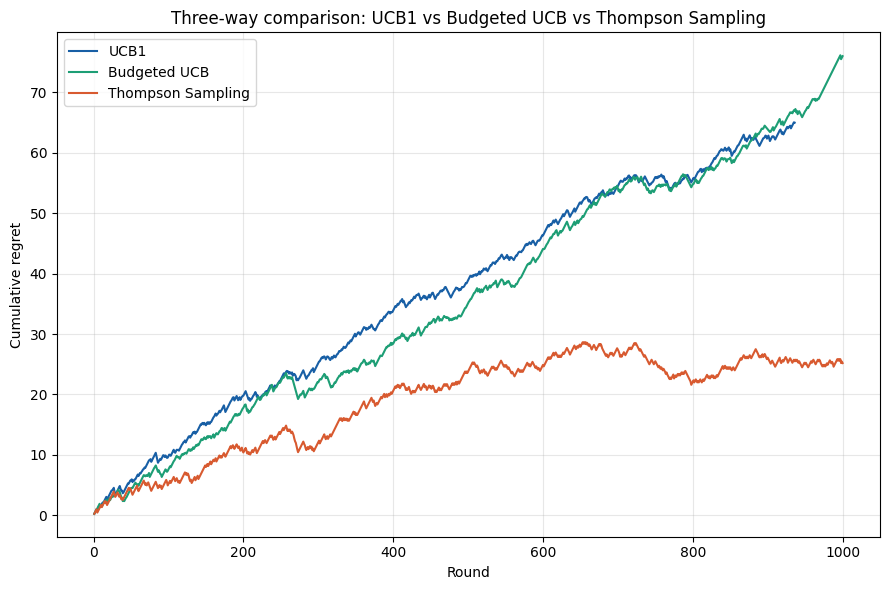

In [26]:
# ── Three-way comparison: UCB1 vs Budgeted UCB vs Thompson Sampling ────────
fig, ax = plt.subplots(figsize=(9, 6))
for df, name, color in [
    (ucb1_df, "UCB1", "#185FA5"),
    (budgeted_ucb_df, "Budgeted UCB", "#1D9E75"),
    (ts_df, "Thompson Sampling", "#D85A30"),
]:
    ax.plot(df["round"], df["cumulative_regret"], label=name, color=color)

ax.set_xlabel("Round")
ax.set_ylabel("Cumulative regret")
ax.set_title("Three-way comparison: UCB1 vs Budgeted UCB vs Thompson Sampling")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / "req1_three_way_regret_comparison.png", dpi=200)
plt.show()

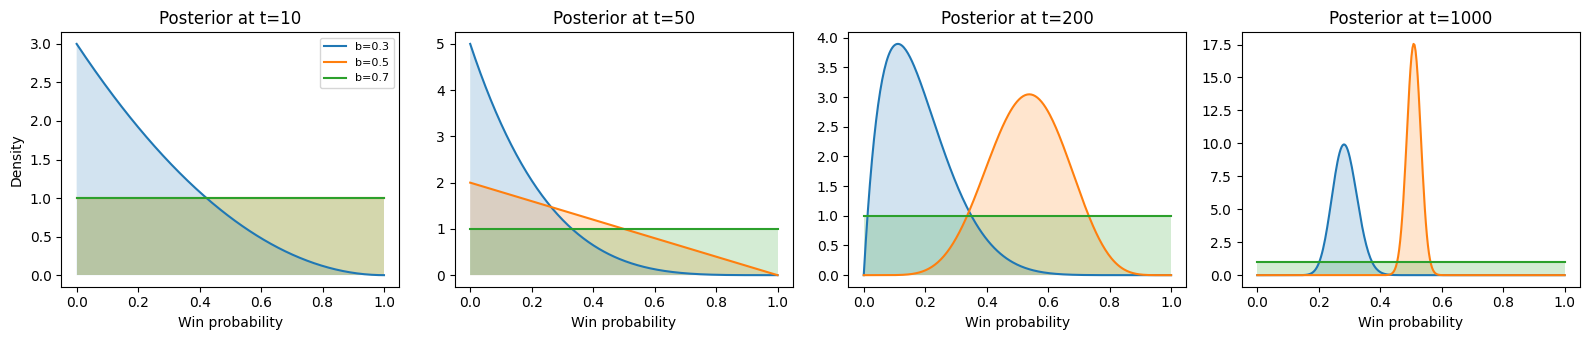

In [27]:
# ── Posterior evolution: how Thompson Sampling's beliefs sharpen over time ─
def plot_beta_pdf(alpha, beta_param, ax, label=None):
    x = np.linspace(0, 1, 300)
    y = beta_dist.pdf(x, alpha, beta_param)
    ax.plot(x, y, label=label)
    ax.fill_between(x, y, alpha=0.2)

bids_to_track = [0.3, 0.5, 0.7]
bid_indices = [np.where(bids == b)[0][0] for b in bids_to_track]
snapshot_rounds_sorted = sorted(ts_agent._posterior_snapshots.keys())

fig, axes = plt.subplots(1, len(snapshot_rounds_sorted), figsize=(16, 3.5))
for col, t in enumerate(snapshot_rounds_sorted):
    alpha_t, beta_t = ts_agent._posterior_snapshots[t]
    for b, idx in zip(bids_to_track, bid_indices):
        plot_beta_pdf(alpha_t[idx], beta_t[idx], axes[col], label=f"b={b}")
    axes[col].set_title(f"Posterior at t={t}")
    axes[col].set_xlabel("Win probability")
    if col == 0:
        axes[col].set_ylabel("Density")
        axes[col].legend(fontsize=8)

plt.tight_layout()
plt.savefig(plots_dir / "req1_ts_posterior_evolution.png", dpi=200)
plt.show()

**Why Thompson Sampling here.** The win event at bid $b$ is Bernoulli with parameter
$p_b = P(b \geq m)$, so a Beta(1,1) prior is conjugate and exact. the posterior over the win probability for b=0.5 visibly sharpens, converging toward its true win probability, consistent with b=0.5 being the analytically optimal bid. This gives a direct
visual account of exploration-exploitation that the regret curve alone doesn't show.

In [28]:
MULTI_SEED_VALUES = list(range(30))


def run_req1_for_seed(seed, budget, label):
    """Run both Req 1 algorithms for one seed and one budget setting."""
    ucb1_benchmark_seed, budgeted_ucb_benchmark_seed = compute_req1_benchmarks(
        bids=bids,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
    )

    ucb1_seed = UCB1(actions=bids, horizon=horizon)
    ucb1_seed_rows = run_algorithm(
        algorithm_name="ucb1",
        learner=ucb1_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=ucb1_benchmark_seed,
    )

    budgeted_ucb_seed = BudgetedUCB(
        actions=bids,
        horizon=horizon,
        initial_budget=budget,
    )
    budgeted_ucb_seed_rows = run_algorithm(
        algorithm_name="budgeted_ucb",
        learner=budgeted_ucb_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=budgeted_ucb_benchmark_seed,
    )

    seed_df = pd.DataFrame(ucb1_seed_rows + budgeted_ucb_seed_rows)
    seed_df["seed"] = seed
    seed_df["budget_setting"] = label
    seed_df["initial_budget"] = budget

    return seed_df


multi_seed_frames = []

for seed in MULTI_SEED_VALUES:
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=initial_budget,
            label="official_budget_B_300",
        )
    )
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=150.0,
            label="tight_budget_B_150",
        )
    )

multi_seed_results = pd.concat(multi_seed_frames, ignore_index=True)

print("Multi-seed result shape:", multi_seed_results.shape)
print("Number of seeds:", multi_seed_results["seed"].nunique())
print("Budget settings:")
print(multi_seed_results["budget_setting"].value_counts())
print("\nAlgorithms:")
print(multi_seed_results["algorithm"].value_counts())

Multi-seed result shape: (103203, 19)
Number of seeds: 30
Budget settings:
budget_setting
official_budget_B_300    58659
tight_budget_B_150       44544
Name: count, dtype: int64

Algorithms:
algorithm
budgeted_ucb    60000
ucb1            43203
Name: count, dtype: int64


In [29]:
multi_seed_summary = (
    multi_seed_results
    .sort_values(["budget_setting", "seed", "algorithm", "round"])
    .groupby(["budget_setting", "initial_budget", "seed", "algorithm"])
    .agg(
        rounds_played=("round", "max"),
        total_reward=("cumulative_reward", "last"),
        total_cost=("cumulative_cost", "last"),
        final_budget_left=("budget_left", "last"),
        final_cumulative_regret=("cumulative_regret", "last"),
    )
    .reset_index()
)

multi_seed_aggregate_summary = (
    multi_seed_summary
    .groupby(["budget_setting", "initial_budget", "algorithm"])
    .agg(
        mean_rounds_played=("rounds_played", "mean"),
        std_rounds_played=("rounds_played", "std"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        mean_total_cost=("total_cost", "mean"),
        std_total_cost=("total_cost", "std"),
        mean_final_budget_left=("final_budget_left", "mean"),
        std_final_budget_left=("final_budget_left", "std"),
        early_stop_rate=("rounds_played", lambda values: float((values < horizon).mean())),
    )
    .reset_index()
)

multi_seed_aggregate_summary

,budget_setting,initial_budget,algorithm,mean_rounds_played,std_rounds_played,mean_total_reward,std_total_reward,mean_total_cost,std_total_cost,mean_final_budget_left,std_final_budget_left,early_stop_rate
0,official_budget_B_300,300.0,budgeted_ucb,1000.0,0.000000,173.746667,9.726775,299.653333,1.281361e+00,3.466667e-01,1.281361e+00,0.000000
1,official_budget_B_300,300.0,ucb1,955.3,27.224672,171.343333,8.083345,299.856667,5.379933e-01,1.433333e-01,5.379933e-01,0.866667
2,tight_budget_B_150,150.0,budgeted_ucb,1000.0,0.000000,83.056667,4.540142,149.910000,3.051286e-02,9.000000e-02,3.051286e-02,0.000000
3,tight_budget_B_150,150.0,ucb1,484.8,100.004965,79.366667,5.149378,150.000000,8.640097e-14,1.017704e-15,5.574197e-15,0.966667


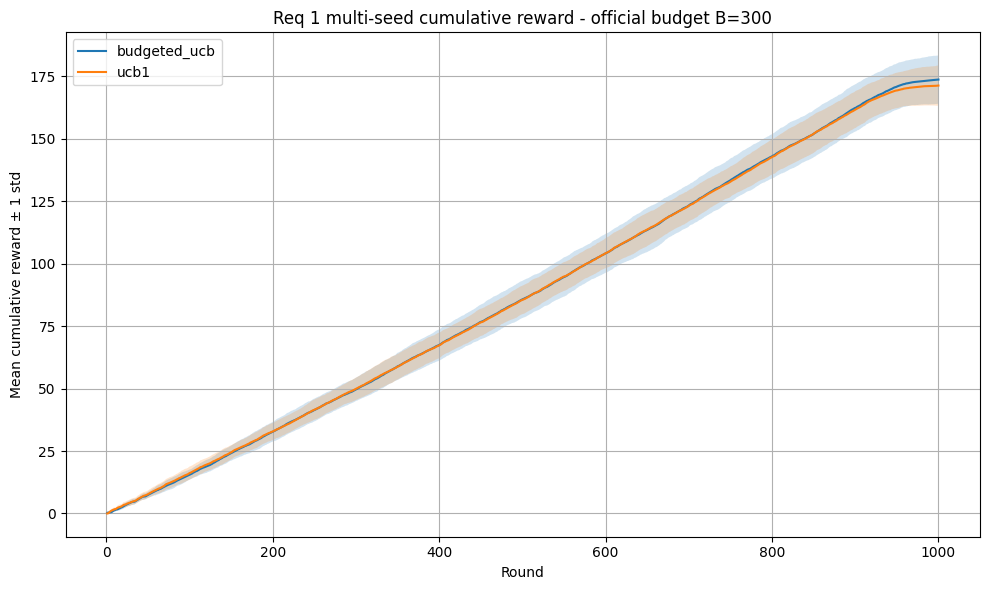

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_official_budget.png
Plot exists: True


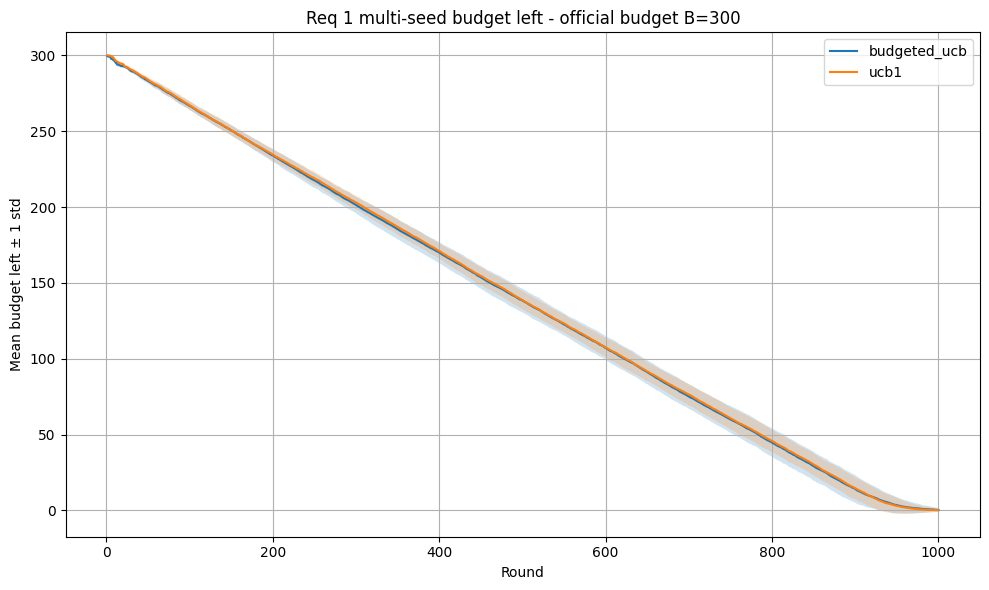

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_official_budget.png
Plot exists: True


In [30]:
def plot_mean_with_std_band(dataframe, budget_setting, metric, ylabel, title, output_filename):
    """Plot mean trajectory with plus/minus one standard deviation over seeds."""
    setting_df = dataframe[dataframe["budget_setting"] == budget_setting]

    plt.figure(figsize=(10, 6))

    for algorithm_name, group in setting_df.groupby("algorithm"):
        pivot = group.pivot_table(
            index="round",
            columns="seed",
            values=metric,
            aggfunc="last",
        ).sort_index()

        # Forward-fill so seeds that stopped early hold their last value
        # instead of disappearing from the mean for the remaining rounds.
        pivot = pivot.reindex(range(1, horizon + 1)).ffill()

        mean_values = pivot.mean(axis=1)
        std_values = pivot.std(axis=1).fillna(0.0)

        rounds = mean_values.index.to_numpy(dtype=float)
        mean_array = mean_values.to_numpy(dtype=float)
        std_array = std_values.to_numpy(dtype=float)

        plt.plot(rounds, mean_array, label=algorithm_name)
        plt.fill_between(
            rounds,
            mean_array - std_array,
            mean_array + std_array,
            alpha=0.2,
        )

    plt.xlabel("Round")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    output_path = plots_dir / output_filename
    plt.savefig(output_path, dpi=200)
    plt.show()

    print("Saved plot to:", output_path)
    print("Plot exists:", output_path.exists())


plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - official budget B=300",
    output_filename="req1_multiseed_reward_official_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - official budget B=300",
    output_filename="req1_multiseed_budget_left_official_budget.png",
)

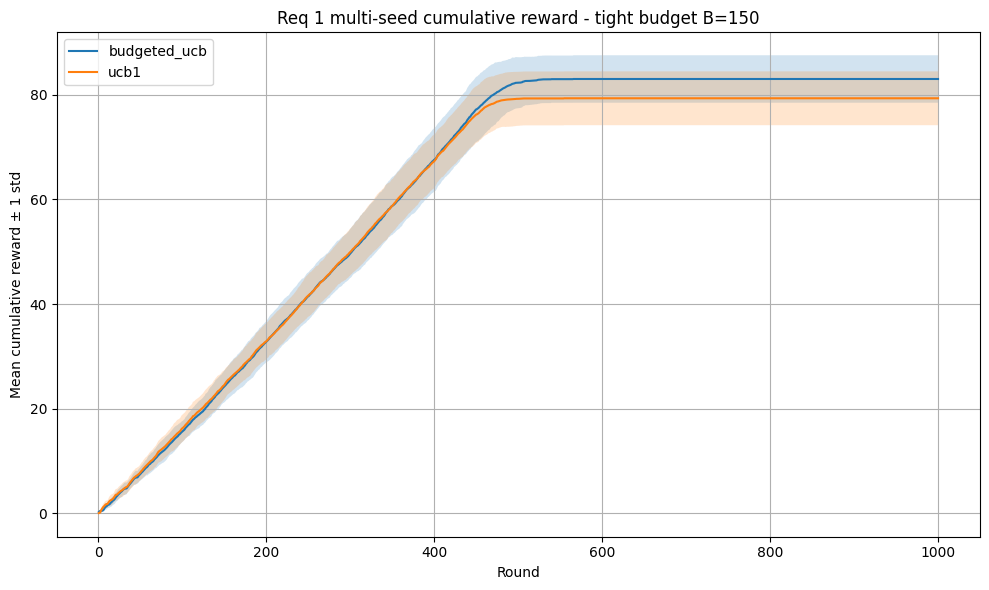

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_tight_budget.png
Plot exists: True


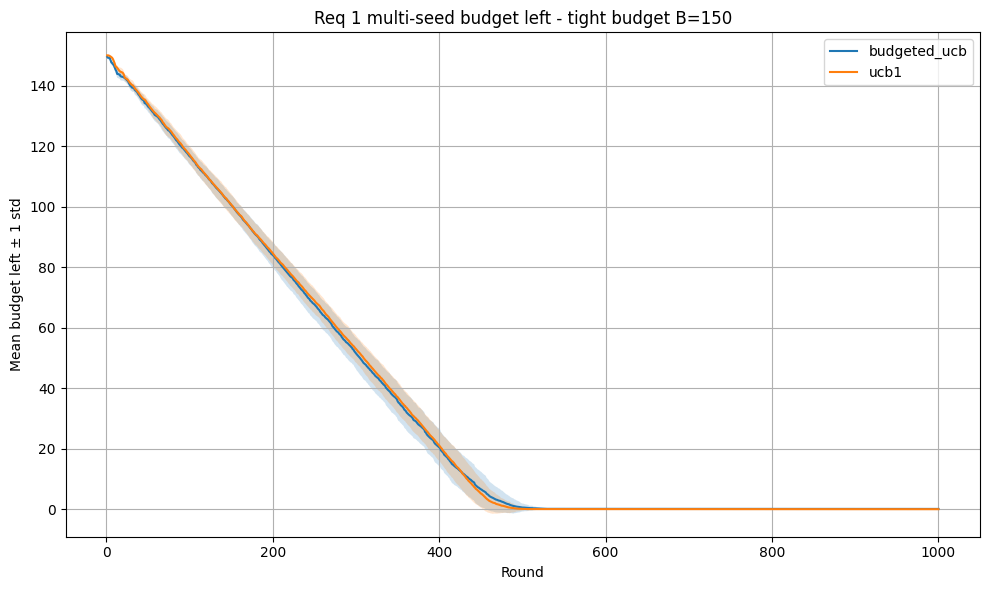

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_tight_budget.png
Plot exists: True


In [31]:
plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - tight budget B=150",
    output_filename="req1_multiseed_reward_tight_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - tight budget B=150",
    output_filename="req1_multiseed_budget_left_tight_budget.png",
)

## Robustness experiment interpretation

The multi-seed experiment repeats the comparison over 30 independent stochastic environments. The solid lines show the average behavior, while the shaded regions represent plus/minus one standard deviation across seeds.

Under the official budget `B = 300`, the two algorithms remain reasonably close in
cumulative reward, with Budgeted UCB obtaining slightly *higher* average reward
(≈173.7 vs ≈171.3) across the 30 seeds. This is consistent with Budgeted UCB's
budget-pacing advantage: UCB1 stops early in the majority of seeds (87% early-stop rate),
forfeiting whatever reward it would have earned in the remaining rounds, while Budgeted
UCB reaches the full horizon in all 30 seeds.

The tighter-budget stress test makes the budget constraint more binding. With `B = 150`, the per-round budget becomes:

$$
\rho = 150/1000 = 0.15.
$$

In this case, the reward-maximizing bid `0.5` is no longer feasible in expectation, because its expected cost is:

$$
\mathbb{E}[\text{cost at } b=0.5] = 0.5 \cdot 0.5 = 0.25 > 0.15.
$$

This explains why budget-aware learning becomes more important in the stress test. UCB1 often depletes the budget around the middle of the horizon, while Budgeted UCB keeps the interaction feasible until the final round.

These additional experiments do not replace the official Req 1 configuration. They strengthen the empirical analysis by showing average behavior, variability across seeds, and performance under a more restrictive budget.

In [32]:
extra_plot_files = [
    "req1_multiseed_reward_official_budget.png",
    "req1_multiseed_budget_left_official_budget.png",
    "req1_multiseed_reward_tight_budget.png",
    "req1_multiseed_budget_left_tight_budget.png",
]

for filename in extra_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_multiseed_reward_official_budget.png exists: True
req1_multiseed_budget_left_official_budget.png exists: True
req1_multiseed_reward_tight_budget.png exists: True
req1_multiseed_budget_left_tight_budget.png exists: True


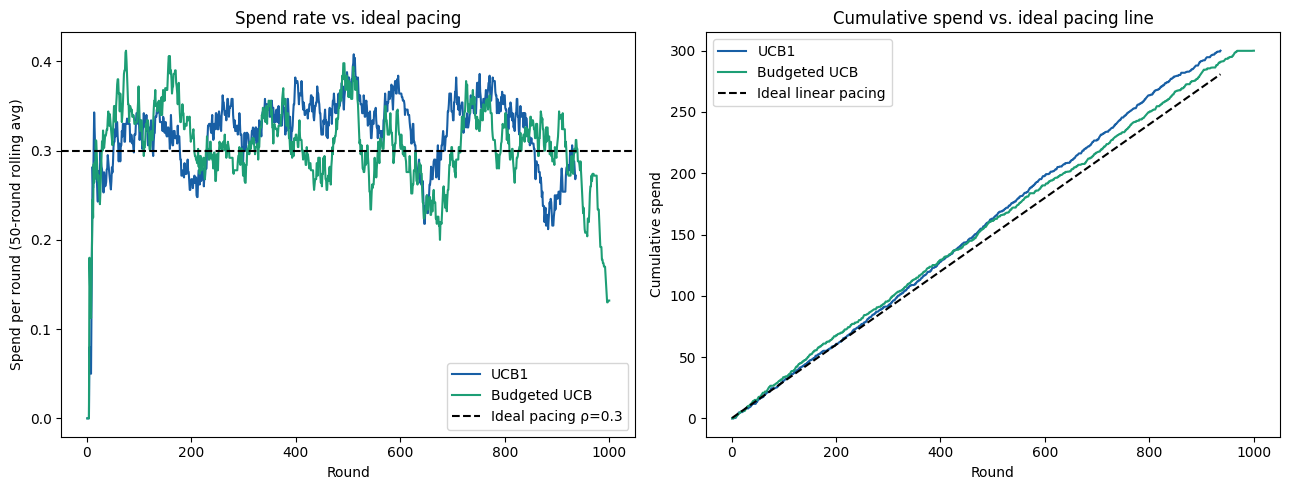

Mean absolute pacing error — UCB1: 10.851
Mean absolute pacing error — Budgeted UCB: 7.733


In [33]:
# ── Budget pacing: spend rate vs. ideal linear pacing ───────────────────────
rho_ideal = initial_budget / horizon
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for df, name, color in [(ucb1_df, "UCB1", "#185FA5"), (budgeted_ucb_df, "Budgeted UCB", "#1D9E75")]:
    rolling_spend = df["cost"].rolling(window=50, min_periods=1).mean()
    axes[0].plot(df["round"], rolling_spend, label=name, color=color)
axes[0].axhline(rho_ideal, color="black", linestyle="--", label=f"Ideal pacing ρ={rho_ideal}")
axes[0].set_xlabel("Round")
axes[0].set_ylabel("Spend per round (50-round rolling avg)")
axes[0].set_title("Spend rate vs. ideal pacing")
axes[0].legend()

for df, name, color in [(ucb1_df, "UCB1", "#185FA5"), (budgeted_ucb_df, "Budgeted UCB", "#1D9E75")]:
    axes[1].plot(df["round"], df["cumulative_cost"], label=name, color=color)
axes[1].plot(ucb1_df["round"], rho_ideal * ucb1_df["round"], "k--", label="Ideal linear pacing")
axes[1].set_xlabel("Round")
axes[1].set_ylabel("Cumulative spend")
axes[1].set_title("Cumulative spend vs. ideal pacing line")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "req1_budget_pacing.png", dpi=200)
plt.show()

pacing_error_ucb1 = (ucb1_df["cumulative_cost"] - rho_ideal * ucb1_df["round"]).abs().mean()
pacing_error_budgeted = (budgeted_ucb_df["cumulative_cost"] - rho_ideal * budgeted_ucb_df["round"]).abs().mean()
print("Mean absolute pacing error — UCB1:", round(pacing_error_ucb1, 3))
print("Mean absolute pacing error — Budgeted UCB:", round(pacing_error_budgeted, 3))

## Requirement 1 completion checklist

Requirement 1 is complete for the current project configuration.

What this notebook verifies:

- The environment is a single-campaign stochastic first-price auction environment.
- The competing bid is sampled from a fixed uniform distribution.
- Rewards and costs follow the first-price auction rule: if the bid wins, reward is `value - bid` and cost is `bid`; otherwise both are zero.
- UCB1 learns over the finite bid set while ignoring the budget constraint.
- Budgeted UCB learns both rewards and costs and uses the budget-aware rule to control spending.
- The shared CSV output format is respected.
- The generated plots compare reward, budget usage, cumulative cost, raw selected bids, and smoothed selected bids.
- The robustness experiment repeats the comparison over 30 independent seeds.
- The robustness experiment reports mean and standard deviation across seeds.
- The tighter-budget stress test shows how the algorithms behave when the budget constraint is more binding.

Main empirical conclusion:

- In the official single-seed configuration, Budgeted UCB reaches the full horizon while
  UCB1 stops early (around round 936) once its budget is exhausted.
- UCB1 spends its entire budget aggressively and without pacing, which causes early
  stopping even in the official (non-binding) budget setting.
- Budgeted UCB paces its spending to land almost exactly on zero budget at the final
  round, rather than overshooting early.
- Across 30 seeds, Budgeted UCB obtains slightly higher average total reward than UCB1,
  primarily because it avoids forfeiting rounds to early stopping.
- The tighter-budget stress test ($B=150$) makes this gap more pronounced: UCB1 stops
  around round 485 on average, while Budgeted UCB still completes all 1000 rounds.

Therefore, the main advantage of Budgeted UCB is budget feasibility and reliable budget
pacing — it consistently uses the full horizon, which translates into a real (if modest)
reward advantage even when the budget constraint is not formally "binding" in expectation.